<a href="https://colab.research.google.com/github/Stephanie490/DATA201-labs/blob/main/Week_8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading Data

In [ ]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values(ascending=False))

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
Salary       59
AtBat         0
HmRun         0
Hits          0
Runs          0
RBI           0
Years         0
Walks         0
CHits         0
CHmRun        0
CRuns         0
CAtBat        0
CRBI          0
CWalks        0
Division      0
League        0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
dtype: int64


Part 1  - Experiment with alpha

In [ ]:
#remove the missing information
# remember to remove salary from training since we are predicting it
hitters = hitters.dropna(subset=['Salary']).copy()

#Set your features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']    # thousands of dollars

#define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


In [ ]:
# Scales numerical vakues and one-hot encodes categorical
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])
# ^ One hot encoding
baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])

baseline.fit(X_train, y_train) # Could be ridge fit and lasso fit

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train) #Same here could be lasso
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }
# We are not predicting category-instead predicting a numerical value. So we do RMSE, R2, etc. instead of Accuracy, F1, etc.
results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


In [ ]:
alpha_examples = [0.1, 10, 100]
rows = []
for kind, estimator in [('Lasso', Lasso(max_iter=30000))]:
    for a in alpha_examples:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train)

        #get the model's coefficients
        coefs = pipe.named_steps['model'].coef_

        #each time the loop runs, we add one dictionary to the list "rows".
        rows.append({
            'Model': kind, 'alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients
            'Coefficient L1 size': float(np.sum(np.abs(coefs))), #sum of the absolute values of all coefficients
            'Test RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))),
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))),
        })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,alpha,Nonzero coefficients,Coefficient L1 size,Test RMSE,Training RMSE
0,Lasso,0.1,19,2589.13,356.83,289.38
1,Lasso,10.0,9,524.31,381.84,303.10
2,Lasso,100.0,5,241.75,395.12,341.39


Part 2: Visualize and Interpret

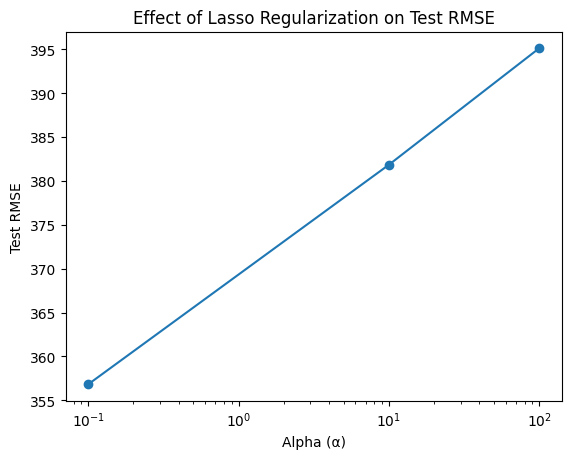

In [ ]:
plt.plot(alpha_table['alpha'], alpha_table['Test RMSE'], marker='o')

plt.xscale('log')

plt.xlabel('Alpha (α)')
plt.ylabel('Test RMSE')
plt.title('Effect of Lasso Regularization on Test RMSE')

plt.show()

Part 3:

1. Which α produces the lowest test RMSE among the three values?

.1 = α produces the lowest test RMSE

2. Which α appears to cause the most underfitting? Explain using bias.

100 = α since it has the highest Test RMSE and therefore high bias. This means the the model is too simple capture all the patterns in the data.

3. Why might a model with higher training RMSE produce lower test RMSE?

Since Regularization can remove correlated variables completely or shrink their coefficient. This can decrease the Test RMSE since it simplifies the model to avoid overfitting

In [ ]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)

lasso_grid = GridSearchCV(
    Pipeline([('preprocess', make_preprocessor()),
              ('model', Lasso(max_iter=30000))]),
    {'model__alpha': np.logspace(-2, 4, 40)},# alpha values. uses 4 instead of 5 because if lasso goes to high is makes coefficents disappear
    scoring='neg_mean_squared_error', cv=cv5, n_jobs=-1
)
lasso_grid.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocess',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['AtBat',
                                                                          'Hits',
                                                                          'HmRun',
                                                                          'Runs',
                                                                          'RBI',
                                                                          'Walks',
                                                                          'Years',
                                                                          'CAtBat',
                                                                          'CHits',
                                                                          'CHmRun',
                                                                          'CRuns',
                                                                          'CRBI',
                                                                          'CWalks',
                                                                          'PutOuts',
                                                                          'Assists',
                                                                          'Errors']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'...
       2.89426612e+00, 4.12462638e+00, 5.87801607e+00, 8.37677640e+00,
       1.19377664e+01, 1.70125428e+01, 2.42446202e+01, 3.45510729e+01,
       4.92388263e+01, 7.01703829e+01, 1.00000000e+02, 1.42510267e+02,
       2.03091762e+02, 2.89426612e+02, 4.12462638e+02, 5.87801607e+02,
       8.37677640e+02, 1.19377664e+03, 1.70125428e+03, 2.42446202e+03,
       3.45510729e+03, 4.92388263e+03, 7.01703829e+03, 1.00000000e+04])},
             scoring='neg_mean_squared_error')

In [ ]:
feature_names = baseline.named_steps['preprocess'].get_feature_names_out()
coef_table = pd.DataFrame({
    'Feature': feature_names,
    'OLS': baseline.named_steps['model'].coef_,
    'Lasso': lasso_grid.best_estimator_.named_steps['model'].coef_
})
coef_table['Lasso is zero'] = np.isclose(coef_table['Lasso'], 0, atol=1e-6)
coef_table = coef_table.sort_values('Lasso', key=lambda s: s.abs(), ascending=False)
display(coef_table.round(2))
print('Number of retained lasso coefficients:', int((~coef_table['Lasso is zero']).sum()))
print('Number dropped by lasso:', int(coef_table['Lasso is zero'].sum()))

,Feature,OLS,Lasso,Lasso is zero
10,num__CRuns,602.97,123.59,False
1,num__Hits,379.23,104.58,False
11,num__CRBI,238.25,69.52,False
13,num__PutOuts,80.70,66.17,False
5,num__Walks,113.43,41.63,False
17,cat__Division_W,-100.03,-19.70,False
0,num__AtBat,-252.65,0.00,True
2,num__HmRun,64.67,0.00,True
6,num__Years,35.91,0.00,True
4,num__RBI,-52.67,0.00,True


Number of retained lasso coefficients: 6
Number dropped by lasso: 13




1. Identify two predictors that Lasso sets to zero at α = 100.

num_HmRun and num_Years


2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary?

No. If a variable's coefficents is set to zero that just mean Lasso removed them becaause there is correlation between the variables.

3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance.

I would prefer the model that has fewer predictors. This would mean the model is more simple and therefore it would avoid overfitting. The simplest model is always preferred since it saves time, saves space, and is easier to explain

Part 4:

- Scenario A: A researcher has data from 80 patients with 200 medical measurements. The
goal is to identify a small number of measurements that may be useful for predicting disease severity.

Lasso. Since the goal is to decrease the number of measurements lasso would be best since it removes redundant or noisey variables from the model

- Scenario B: A company wants to predict employee salaries using 40 predictors. Many
predictors are strongly correlated, and the company believes most contain useful
information. Keeping all predictors is not a concern.

Ordinary Linear Regression. Since the company is okay with keeping correlated predictors, linear  regression is best since it does not shrink any variables. Also you can see the true weight of each variable and how it effects the target. However the variables would have to be numerical.

- Scenario C: A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is
easy to interpret.

Ordinary Linear Regression. Neither ridge nor lasso are necessary since there are only 3 variables and the researcher prefers the simplest model.

- Scenario D: A company has 500 observations and 25 predictors. It is unclear how many
predictors are useful or how strongly they are correlated. The company wants the most
accurate predictions possible.

Note sure. Since it is unknown what predictors are useful and which are correlated, there is not enough information to make a decision. Cross validation can be used to see which model(ridge,lasso, or ordinary linear regression) has the lowest error.